In [8]:
Pkg.add("IterativeSolvers")

   Resolving package versions...
   Installed IterativeSolvers ─ v0.9.4
    Updating `~/.julia/environments/v1.13/Project.toml`
  [42fd0dbc] + IterativeSolvers v0.9.4
    Updating `~/.julia/environments/v1.13/Manifest.toml`
  [42fd0dbc] + IterativeSolvers v0.9.4
Precompiling packages...
   1.0 s  ✓ IterativeSolvers
  1 dependency successfully precompiled in 1 seconds. 11 already precompiled.


In [1]:
using Roots, QuantEcon, LinearAlgebra, Plots, Parameters, ForwardDiff, IterativeSolvers

In [40]:
function setup(;
    β = 0.98,
    α = 0.4,
    γ = 2.0,
    δ = 0.02,
    ρ = 0.95,
    σ_z = 1.0,
    N_x = 5)
    return (β = β, α = α, γ = γ, δ = δ, ρ = ρ, σ_z = σ_z, N_x = N_x)
end

params = setup()
function steadystate(params)
    @unpack β, α, γ, δ, ρ, σ_z, N_x = params
    rss = 1.0/β + δ - 1.0
    Lss = 1.0
    Zss = 1.0
    Kss = ((α*Zss*Lss)/rss )^(1.0/(1.0-α))
    Yss = Zss*Kss^α*Lss^(1.0-α)
    Css = Yss-δ*Kss
    return (Zss = Zss, Kss = Kss, rss = rss, Yss = Yss, Css = Css)
end
Xss = steadystate(params)
Xss = [Xss...]
function F_sys(X_p, X, X_l, shocks, params)
    @unpack β, α, γ, δ, ρ, σ_z, N_x = params
            Z_l, K_l, r_l, Y_l, C_l = X_l
            Z, K, r, Y, C = X
            Z_p, K_p, r_p, Y_p, C_p = X_p
            ϵ = shocks[1]
        F_1 = C^(-γ) - β*(C_p^(-γ)*(1.0-δ+α*Z_p*K^(α-1.0)))
        F_2 = r-α*Z*K_l^(α-1.0)
        F_3 = Y-Z*K_l^α
        F_4 = K -(1.0-δ)*K_l - Y + C 
        F_5 = log(Z) - ρ*log(Z_l)-σ_z*ϵ
        return vcat(F_1, F_2, F_3, F_4, F_5)
end
Fss = F_sys(Xss, Xss, Xss, [0.0], params)
A = ForwardDiff.jacobian(t -> F_sys(t, Xss, Xss,[0.0], params), Xss)
B = ForwardDiff.jacobian(t -> F_sys(Xss, t, Xss,[0.0], params), Xss)
C = ForwardDiff.jacobian(t -> F_sys(Xss, Xss,t,[0.0], params), Xss)
D = ForwardDiff.jacobian(t -> F_sys(Xss, Xss, Xss, t, params), [0.0])
function LinearTimeIiteration(A,B,C,D; maxit = 10000, tol = 1e-8)
    P0 = fill(0.0, size(A))
    S0 = fill(0.0, size(C))
    for it in 1:maxit
        P1 = -(A*P0+B)\C 
        S1 = -(C*S0+B)\A 
        if maximum(abs.(P1 - P0))< tol
            break
        end
        P0 = P1
        S0 = S1
    end
    Q = -(A*P0+B)\D 
    eigen_P = eigen(P0)
    eigen_S = eigen(S0)
    if maximum(abs.(eigen_P.values)) > 1.0
        error("Non existence")
    end
    if maximum(abs.(eigen_S.values)) > 1.0
        error("No stable equilibrium")
    end
    return P0, Q
end
P, Q = LinearTimeIiteration(A, B, C, D)
G = Matrix(I,size(P))
X_sim,_ = simulate(LSS(P,Q,G),200)

([0.0 -0.2932815812827128 … 4.779473485336286 3.788234395688054; 0.0 -0.9412290125896806 … 291.2976241599675 297.0094501445063; … ; 0.0 -1.352110057564297 … 33.43802872721779 29.23562127528695; 0.0 -0.4108810449746164 … 18.699714901492463 17.69784280754881], [0.0 -0.2932815812827128 … 4.779473485336286 3.788234395688054; 0.0 -0.9412290125896806 … 291.2976241599675 297.0094501445063; … ; 0.0 -1.352110057564297 … 33.43802872721779 29.23562127528695; 0.0 -0.4108810449746164 … 18.699714901492463 17.69784280754881])

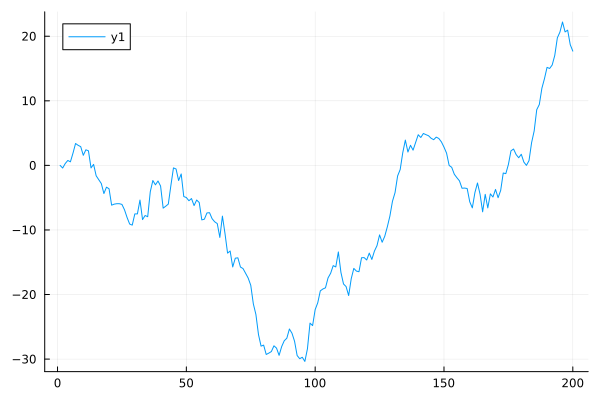

In [45]:
plot(X_sim[5,:])

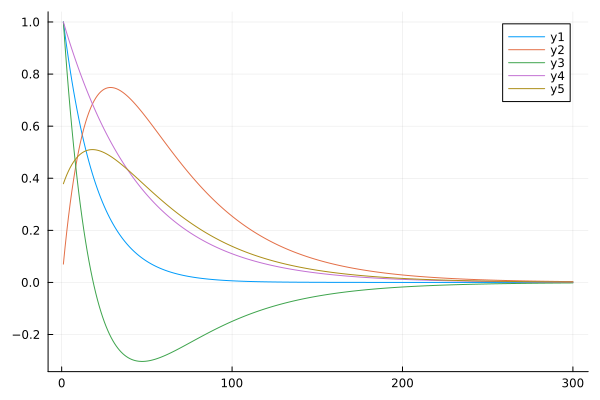

In [55]:
Irf_X = zeros(size(P,1),300)
Irf_X[:,1] = Q
for t = 2:300
    Irf_X[:,t] = P*Irf_X[:,t-1]
end
plot(Irf_X[1,:]./Xss[1])
plot!(Irf_X[2,:]./Xss[2])
plot!(Irf_X[3,:]./Xss[3])
plot!(Irf_X[4,:]./Xss[4])
plot!(Irf_X[5,:]./Xss[5])